In [2]:
import numpy as np
import matplotlib.pyplot as plt
import math


n_cells = 500

t_final = 1.0e-4
# t_final = 1.0e-5

x = np.linspace(0, 1, n_cells+1)
x_center = 0.5 * (x[:-1] + x[1:])
h = x[1] - x[0]

x0 = 0.4

x_split = 0.5


# ion_density = np.zeros(n_cells)
# ion_density[x_center <= x_split] = 1.0e20
# ion_density[x_center >= x_split] = 1.0e21
# ion_density = np.logspace(20, 21, n_cells)
ion_density = 1.0e20 - 5.0e19 * np.sin(math.pi * x_center)
# ion_density = 1.0e21 * np.ones(n_cells)

ion_velocity = np.zeros(n_cells)

ion_temperature = np.zeros(n_cells)
ion_temperature[:] = 1.0

def get_index(x):
    return int(x * n_cells)

def get_BGK_stddev(T):
    return np.sqrt(T * 1.602176634e-19 / 1.67e-27)

def get_collision_rate(T, dens):
    return 3.2e-15 * np.sqrt(T/0.026) * dens

In [3]:
## Normal monte-carlo

n_particles = 100
density_mc = np.zeros(n_cells, dtype=float)
h = 1/n_cells
for i in range(n_particles):
    x_particle = x0
    x_index = get_index(x_particle)
    t = 0
    v = np.random.normal(ion_velocity[x_index], get_BGK_stddev(ion_temperature[x_index]))

    while t < t_final:
        # time till next collision
        collision_rate = get_collision_rate(ion_temperature[x_index], ion_density[x_index])
        eps = np.random.rand()
        tc = -np.log(eps) / collision_rate
        tc = min(tc, t_final - t)

        # calculate time till cell crossing
        t_boundary = np.inf
        if v > 0:
            t_boundary = ((x_index + 1) * h - x_particle) / v
        elif v < 0:
            t_boundary = (x_index * h - x_particle) / v

        if t_boundary < tc:
            # move particle to boundary

            if(v > 0):
                x_particle = (x_index + 1) * h
                x_index += 1
                if(x_index == n_cells):
                    # We've hit the right boundary
                    # reflect
                    x_index -= 1
                    v = -v
            else:
                x_particle = x_index * h
                x_index -= 1
                if(x_index < 0):
                    # We've hit the left boundary
                    # reflect
                    x_index = 0
                    v = -v

            t += t_boundary
            continue

        # move particle
        x_particle += v * tc
        # draw new velocity
        v = np.random.normal(ion_velocity[x_index], get_BGK_stddev(ion_temperature[x_index]))
        t += tc

    # tally final position
    volume = 1/(n_cells)
    density_mc[x_index] += 1/volume / n_particles

In [4]:
## Calculate reference solution using eigrene

import subprocess
import json

config = {}

config["mesh"] = {
    "type": "voxel",
    "Lx": 1,
    "Ly": 1,
    "Lz": 1,
    "nx": n_cells,
    "ny": 1,
    "nz": 1,
}

config["background"] = {
    "plasma_dens": ion_density.tolist(),
    "plasma_temp": ion_temperature.tolist(),
    "plasma_vel_x": ion_velocity.tolist(),
    "plasma_vel_y": np.zeros(n_cells, dtype=np.float64).tolist(),
    "plasma_vel_z": np.zeros(n_cells, dtype=np.float64).tolist(),
}

x0_index = get_index(x0)
bgk_stddev = get_BGK_stddev(ion_temperature[x0_index])
x0_velocity = ion_velocity[x0_index]
config["sources"] = [
    {
        "type": "point",
        "n_particles": 1000000,
        "intensity": 1.0,
        "pos": [x0, 0.5, 0.5],
        "vel_mean": [x0_velocity, 0, 0],
        "vel_stddev": bgk_stddev,
    },
]

config["boundary_conditions"] = [
    "reflective",
    "reflective",
    "reflective",
    "reflective",
    "reflective",
    "reflective",
]

config["t_final"] = t_final
config["max_steps"] = 10000000
config["seed"] = 0


inputstring = json.dumps(config)

with open("input.json", "w") as f:
    f.write(inputstring)

subprocess.check_output(["../build/main_json"]).decode("utf-8")

with open("output.json", "r") as f:
    outputstring = f.read()

output = json.loads(outputstring)

stats = output["stats"]
print(stats)

density_mc2 = np.array(output["density"])

{'grid_building_time': 1.3704e-05, 'num_collisions': 107668124, 'num_crossings': 390671270, 'total_time': 8.30348008, 'trace_time': 8.303466376}


In [5]:
## Simple KD simulation

n_particles = 100000
density_kd = np.zeros(n_cells, dtype=float)
h = 1/n_cells
dt_kd = 1.0e-4

for i in range(n_particles):
    x_particle = x0
    x_index = get_index(x_particle)
    t = 0
    v = np.random.normal(ion_velocity[x_index], get_BGK_stddev(ion_temperature[x_index]))

    while t < t_final:

        #
        # Part 1: simulate kinetically until the next collision
        #
        t_next = t + dt_kd

        while t < t_next:

            # time till next collision
            collision_rate = get_collision_rate(ion_temperature[x_index], ion_density[x_index])
            eps = np.random.rand()
            tc = -np.log(eps) / collision_rate
            tc = min(tc, t_final - t)

            # calculate time till cell crossing
            t_boundary = np.inf
            if v > 0:
                t_boundary = ((x_index + 1) * h - x_particle) / v
            elif v < 0:
                t_boundary = (x_index * h - x_particle) / v

            if t_boundary < tc:
                # move particle to boundary
                if(v > 0):
                    x_particle = (x_index + 1) * h
                    x_index += 1
                    if(x_index >= n_cells):
                        # We've hit the right boundary
                        # reflect
                        x_index = n_cells - 1
                        v = -v
                else:
                    x_particle = x_index * h
                    x_index -= 1
                    if(x_index < 0):
                        # We've hit the left boundary
                        # reflect
                        x_index = 0
                        v = -v

                t += t_boundary
                continue

            # move particle
            x_particle += v * tc
            # draw new velocity
            v = np.random.normal(ion_velocity[x_index], get_BGK_stddev(ion_temperature[x_index]))
            t += tc
            break

        #
        # Part 2: simulate fluidly until the next collision
        #
        t_diffusive = t_next - t

        if(t_diffusive > 0):

            # draw next position from analytical solution
            drift_term = ion_velocity[x_index] * t_diffusive

            Rcx = get_collision_rate(ion_temperature[x_index], ion_density[x_index])
            Rcxtheta = Rcx * t_diffusive
            D = get_BGK_stddev(ion_temperature[x_index])**2 / (Rcx * Rcxtheta) * (np.exp(-Rcxtheta) - 1. + Rcxtheta)
            if(D < 0):
                D = 0
            D = np.sqrt(2. * D * t_diffusive)
            diffusion_term = D * np.random.normal(0, 1)

            x_particle_new = x_particle + drift_term + diffusion_term
            # check if we are outside the domain
            # if so, reflect, this should be correct as it results
            # in the same distribution as the method of images
            # which is exact in 1D
            if(x_particle_new < 0):
                x_particle_new = -x_particle_new
            if(x_particle_new > 1):
                x_particle_new = 1 - (x_particle_new - 1)

            x_index_new = get_index(x_particle_new)

            # Only accept new position if it is within the domain
            if x_index_new < 0 or x_index_new >= n_cells:
                continue

            x_particle = x_particle_new
            x_index = x_index_new
            t += t_diffusive

    # tally final position
    volume = 1/(n_cells)
    density_kd[x_index] += 1/volume / n_particles

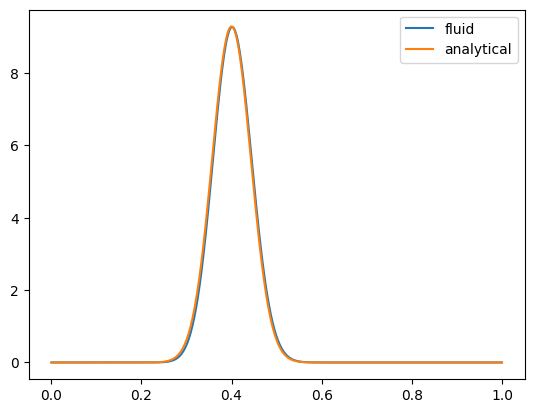

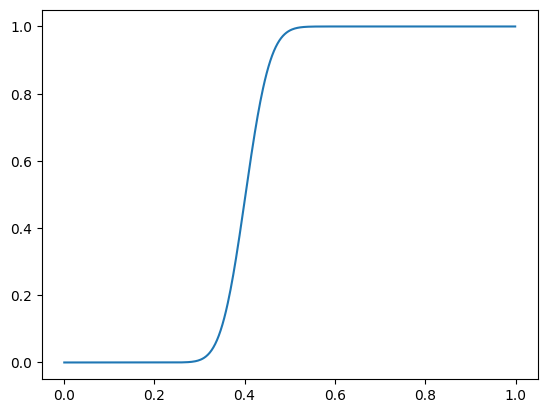

In [21]:

#
# Step 1 of the new KD scheme: precalculate the finite volume solution with starting position in each cell
#
h = 1/n_cells

dt_fluid = 1.0e-5
dt_fluid_internal = 1.0e-7

# step 1: construct matrix A
B = np.zeros((n_cells, n_cells), dtype=np.float64)
for i in range(0, n_cells):
    D = get_BGK_stddev(ion_temperature[i])**2 / get_collision_rate(ion_temperature[i], ion_density[i])
    r = dt_fluid_internal / h**2 * D
    if i == 0:
        B[i, i] = -r
        B[i, i+1] = r
    elif i == n_cells - 1:
        B[i, i] = -r
        B[i, i-1] = r
    else:
        B[i, i] = -2 * r
        B[i, i-1] = r
        B[i, i+1] = r

A1 = np.eye(n_cells, dtype=np.float64) + 0.5 * B
A2 = np.eye(n_cells, dtype=np.float64) - 0.5 * B

# step 2: set initial condition
density_fluid = np.zeros((n_cells, n_cells), dtype=np.float64)

for i in range(n_cells):
    density_fluid[i, i] = n_cells

# step 3: time integration

t = 0
while t < dt_fluid:
    density_fluid = np.linalg.solve(A2, A1 @ density_fluid)
    t += dt_fluid_internal

#
# override with analytical solution for testing
#
# for i in range(n_cells):
#     D = get_BGK_stddev(ion_temperature[i])**2 / get_collision_rate(ion_temperature[i], ion_density[i])
#     x00 = x_center[i]
#     density_fluid[i, :] = 1. / np.sqrt(4 * math.pi * D * dt_fluid) * np.exp(-(x_center - x00)**2 / (4 * D * dt_fluid))

# step 3.5: Make sure the integral is 1
for i in range(n_cells):
    density_fluid[i, :] /= np.sum(density_fluid[i, :]) * h

# step 4: transform it into cumulative distribution
density_fluid_cumulative = np.zeros((n_cells, n_cells), dtype=np.float64)

density_fluid_cumulative[0, :] = density_fluid[0, :] * h
for i in range(n_cells):
    density_fluid_cumulative[i, :] = density_fluid_cumulative[i-1, :] + density_fluid[i, :] * h

# Make sure the last cell is 1
density_fluid_cumulative[-1, :] = 1

density_fluid_cumulative2 = np.zeros((n_cells, n_cells), dtype=np.float64)
density_fluid_cumulative2[0, :] = density_fluid[0, :] * h / 2
for i in range(1, n_cells):
    density_fluid_cumulative2[i, :] = density_fluid_cumulative2[i-1, :] + (density_fluid[i-1, :] + density_fluid[i, :]) * h / 2

# Rescale so the last cell is 1
for i in range(n_cells):
    density_fluid_cumulative2[:, i] /= density_fluid_cumulative2[-1, i]


# density_fluid_cumulative2[-1, :] = 1

# step 5: finish up the time integration till t_final
# this is not necessary for kd, but makes the plotting later possible
# while t < t_final:
#     density_fluid = np.linalg.solve(A, density_fluid)
#     t += dt_fluid_internal


# compare fluid and analytical solution
density_fluid_final = density_fluid[:, get_index(x0)]
plt.figure()
plt.plot(x_center, density_fluid_final, label="fluid")

x_center_analytical = np.linspace(0, 1, 400)
D = get_BGK_stddev(ion_temperature[x0_index])**2 / get_collision_rate(ion_temperature[x0_index], ion_density[x0_index])
density_analytical = 1. / np.sqrt(4 * math.pi * D * dt_fluid) * np.exp(-(x_center_analytical - x0)**2 / (4 * D * dt_fluid))
density_analytical += 1. / np.sqrt(4 * math.pi * D * dt_fluid) * np.exp(-(x_center_analytical + x0 - 2)**2 / (4 * D * dt_fluid))

plt.plot(x_center_analytical, density_analytical, label="analytical")
plt.legend()


plt.figure()
plt.plot(x_center, density_fluid_cumulative2[:, get_index(x0)], label='Fluid')
plt.show()

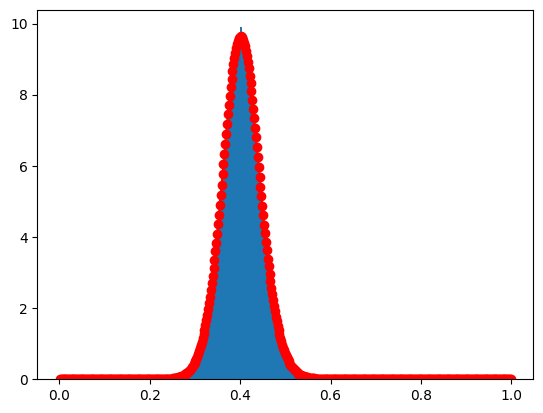

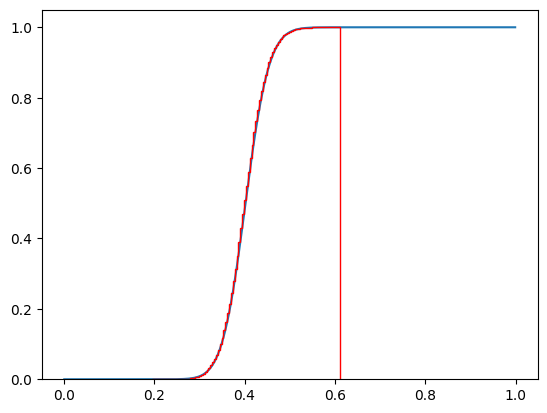

In [7]:
# Test the sampling

n_particles = 100000

positions = np.zeros(n_particles, dtype=np.float64)

x_index = get_index(x0)

for i in range(n_particles):
    # Draw uniform random number
    eps = np.random.rand()

    # The cumulative distribution is defined in density_fluid_cumulative[:, x_index]
    # We need to find the ind so that density_fluid_cumulative[ind + 1, x_index] > eps
    # The cumulative distribution is monotonically increasing, so we could do a binary search
    # But I use a simple loop for now
    ind = 0
    while density_fluid_cumulative2[ind+1, x_index] < eps:
        ind += 1

    # now, cdf[ind] <= eps < cdf[ind+1]
    # x is somewhere between x_center[ind] and x_center[ind+1]
    # the pdf is a linear interpolation, so the cdf is a quadratic interpolation
    # we need to solve a quadratic equation to find the exact position

    a = (density_fluid[ind+1, x_index] - density_fluid[ind, x_index]) / (2 * h)
    b = density_fluid[ind, x_index]
    c = density_fluid_cumulative2[ind, x_index] - eps

    # solve the quadratic equation
    x_particle = (-b + np.sqrt(b**2 - 4 * a * c)) / (2 * a)
    x_particle += ind * h + h/2
    # x_particle = ind * h + h / 2 + h * np.random.rand()

    positions[i] = x_particle




plt.figure()
plt.hist(positions, bins=100, density=True)
# plt.stairs(density_fluid_cumulative[:, get_index(x0)], x)
# plt.plot(x_center - h / 2, density_fluid_cumulative[:, get_index(x0)], label='Fluid', color='black')
plt.plot(x_center, density_fluid[:, get_index(x0)], 'ro-')

plt.figure()
plt.plot(x_center, density_fluid_cumulative2[:, get_index(x0)], label='Fluid')
plt.hist(positions, bins=100, density=True, cumulative=True, histtype='step', color='red')
plt.show()

In [22]:
n_particles = 100000
density_kd2 = np.zeros(n_cells, dtype=float)
dt_kd = 5.0e-5
for i in range(n_particles):
    x_particle = x0
    x_index = get_index(x_particle)
    t = 0
    v = np.random.normal(ion_velocity[x_index], get_BGK_stddev(ion_temperature[x_index]))

    while t < t_final:

        #
        # Part 1: simulate kinetically until the next collision
        #
        t_next = t + dt_kd

        while t < t_next:

            # time till next collision
            collision_rate = get_collision_rate(ion_temperature[x_index], ion_density[x_index])
            eps = np.random.rand()
            tc = -np.log(eps) / collision_rate
            tc = min(tc, t_final - t)

            # calculate time till cell crossing
            t_boundary = np.inf
            if v > 0:
                t_boundary = ((x_index + 1) * h - x_particle) / v
            elif v < 0:
                t_boundary = (x_index * h - x_particle) / v

            if t_boundary < tc:
                # move particle to boundary
                if(v > 0):
                    x_particle = (x_index + 1) * h
                    x_index += 1
                    if(x_index >= n_cells):
                        # We've hit the right boundary
                        # reflect
                        x_index = n_cells - 1
                        v = -v
                else:
                    x_particle = x_index * h
                    x_index -= 1
                    if(x_index < 0):
                        # We've hit the left boundary
                        # reflect
                        x_index = 0
                        v = -v

                t += t_boundary
                continue

            # move particle
            x_particle += v * tc
            # draw new velocity
            v = np.random.normal(ion_velocity[x_index], get_BGK_stddev(ion_temperature[x_index]))
            t += tc
            break

        #
        # Part 2: use precalculated fluid solution for the rest of the timestep
        #

        while t + dt_fluid < t_next:

            # # Draw uniform random number
            # eps = np.random.rand()

            # The cumulative distribution is defined in density_fluid_cumulative[:, x_index]
            # We need to find the x_index_new such that density_fluid_cumulative[x_index_new, x_index] > eps
            # The cumulative distribution is monotonically increasing, so we can do a binary search
            # left = 0
            # right = n_cells - 1
            # while right - left > 1:
            #     mid = (left + right) // 2
            #     if density_fluid_cumulative[mid, x_index] > eps:
            #         right = mid
            #     else:
            #         left = mid
            # x_index_new = right
            # x_index_new = 0
            # while density_fluid_cumulative[x_index_new, x_index] < eps:
            #     x_index_new += 1

            # # for now, randomly place the particle in the cell
            # # maybe we should treat the cumulative distribution as piecewise linear?
            # x_particle = (x_index_new + np.random.rand()) * h
            # x_index = x_index_new
            # t += dt_fluid

            # Draw uniform random number
            eps = np.random.rand()

            # The cumulative distribution is defined in density_fluid_cumulative[:, x_index]
            # We need to find the ind so that density_fluid_cumulative[ind + 1, x_index] > eps
            # The cumulative distribution is monotonically increasing, so we could do a binary search
            # But I use a simple loop for now
            ind = 0
            while density_fluid_cumulative2[ind+1, x_index] < eps:
                ind += 1

            # now, cdf[ind] <= eps < cdf[ind+1]
            # x is somewhere between x_center[ind] and x_center[ind+1]
            # the pdf is a linear interpolation, so the cdf is a quadratic interpolation
            # we need to solve a quadratic equation to find the exact position

            a = (density_fluid[ind+1, x_index] - density_fluid[ind, x_index]) / (2 * h)
            b = density_fluid[ind, x_index]
            c = density_fluid_cumulative2[ind, x_index] - eps

            # solve the quadratic equation
            disc = b**2 - 4 * a * c
            if(disc < 0):
                # Disc is negative, this shouldn't happen
                # Just place the particle in the middle of the cell
                x_particle = (ind + 0.5) * h
            else:
                x_particle = (-b + np.sqrt(b**2 - 4 * a * c)) / (2 * a)
                x_particle += ind * h + h / 2
            # x_particle = ind * h + h / 2 + h * np.random.rand()

            if(x_particle < 0):
                x_particle = 0
            if(x_particle > 1):
                x_particle = 0.99999
            x_index = get_index(x_particle)
            t += dt_fluid

    # tally final position
    volume = 1/(n_cells)
    density_kd2[x_index] += 1/volume / n_particles

In [9]:
## KD simulation, but with smaller fluid timesteps

n_particles = 100000
density_kd3 = np.zeros(n_cells, dtype=float)
h = 1/n_cells
dt_kd = 1.0e-5
dt_fluidsteps = 1.0e-6


for i in range(n_particles):
    x_particle = x0
    x_index = get_index(x_particle)
    t = 0
    v = np.random.normal(ion_velocity[x_index], get_BGK_stddev(ion_temperature[x_index]))

    while t < t_final:

        #
        # Part 1: simulate kinetically until the next collision
        #
        t_next = t + dt_kd

        while t < t_next:

            # time till next collision
            collision_rate = get_collision_rate(ion_temperature[x_index], ion_density[x_index])
            eps = np.random.rand()
            tc = -np.log(eps) / collision_rate
            tc = min(tc, t_final - t)

            # calculate time till cell crossing
            t_boundary = np.inf
            if v > 0:
                t_boundary = ((x_index + 1) * h - x_particle) / v
            elif v < 0:
                t_boundary = (x_index * h - x_particle) / v

            if t_boundary < tc:
                # move particle to boundary
                if(v > 0):
                    x_particle = (x_index + 1) * h
                    x_index += 1
                    if(x_index >= n_cells):
                        # We've hit the right boundary
                        # reflect
                        x_index = n_cells - 1
                        v = -v
                else:
                    x_particle = x_index * h
                    x_index -= 1
                    if(x_index < 0):
                        # We've hit the left boundary
                        # reflect
                        x_index = 0
                        v = -v

                t += t_boundary
                continue

            # move particle
            x_particle += v * tc
            # draw new velocity
            v = np.random.normal(ion_velocity[x_index], get_BGK_stddev(ion_temperature[x_index]))
            t += tc
            break

        #
        # Part 2: simulate fluidly until the next collision
        #
        t_diffusive = t_next - t

        if(t_diffusive > 0):

            while(t < t_next):
                dt_fluidsteps2 = min(dt_fluidsteps, t_next - t)

                # draw next position from analytical solution
                drift_term = ion_velocity[x_index] * dt_fluidsteps2

                Rcx = get_collision_rate(ion_temperature[x_index], ion_density[x_index])
                Rcxtheta = Rcx * t_diffusive
                D = get_BGK_stddev(ion_temperature[x_index])**2 / (Rcx * Rcxtheta) * (np.exp(-Rcxtheta) - 1. + Rcxtheta)
                if(D < 0):
                    D = 0
                D = np.sqrt(2. * D * dt_fluidsteps2)
                diffusion_term = D * np.random.normal(0, 1)

                x_particle_new = x_particle + drift_term + diffusion_term
                # check if we are outside the domain
                # if so, reflect, this should be correct as it results
                # in the same distribution as the method of images
                # which is exact in 1D
                if(x_particle_new < 0):
                    x_particle_new = -x_particle_new
                if(x_particle_new > 1):
                    x_particle_new = 1 - (x_particle_new - 1)

                x_index_new = get_index(x_particle_new)

                # # Only accept new position if it is within the domain
                # if x_index_new < 0 or x_index_new >= n_cells:
                #     continue

                x_particle = x_particle_new
                x_index = x_index_new
                t += dt_fluidsteps2

    # tally final position
    volume = 1/(n_cells)
    density_kd3[x_index] += 1/volume / n_particles

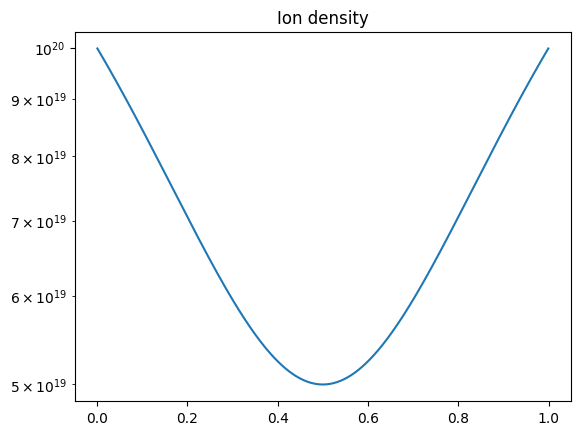

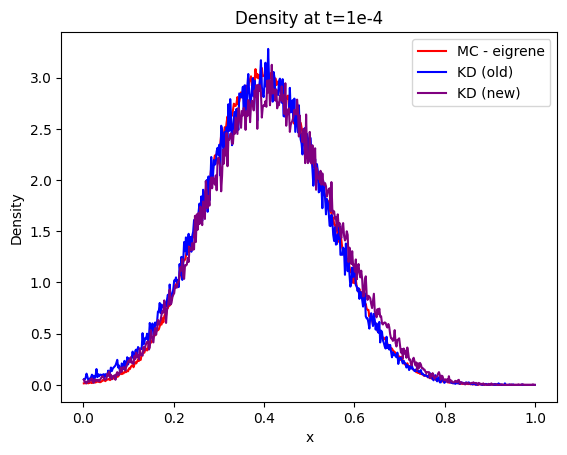

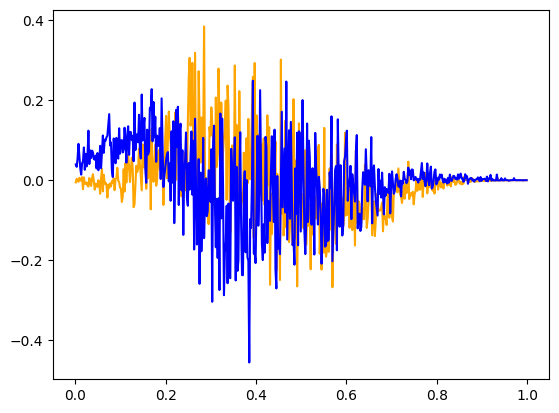

In [23]:
# plt.stairs(density_mc, x, label='MC - python', fill=True, alpha=0.5, color='green')
# plt.stairs(density_mc2, x, label='MC - eigrene', fill=True, alpha=0.5, color='red')
# plt.stairs(density_kd, x, label='KD', fill=True, alpha=0.5, color='blue')
# plt.stairs(density_mc, x, color='green')
# plt.stairs(density_mc2, x, color='red')
# plt.stairs(density_kd, x, color='blue')

plt.figure()
plt.semilogy(x_center, ion_density)
plt.title('Ion density')

plt.figure()
# plt.plot(x_center, density_mc, label='MC - python', color='green')
plt.plot(x_center, density_mc2, label='MC - eigrene', color='red')
plt.plot(x_center, density_kd, label='KD (old)', color='blue')
plt.plot(x_center, density_kd2, label='KD (new)', color='purple')
# plt.plot(x_center, density_kd3, label='KD (diffusion)', color='orange')
# plt.plot(x_center, density_fluid[:, get_index(x0)], label='Fluid', color='black')
plt.legend()
plt.xlabel('x')
plt.ylabel('Density')
plt.title('Density at t=1e-4')

plt.figure()

plt.plot(x_center, density_kd3 - density_mc2, label='KD (diffusion) - MC (eigrene)', color='orange')
plt.plot(x_center, density_kd - density_mc2, label='KD (old) - MC (eigrene)', color='blue')

plt.show()